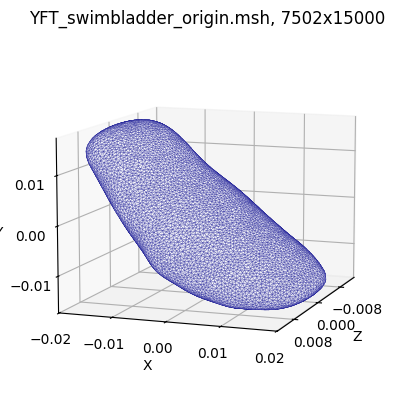

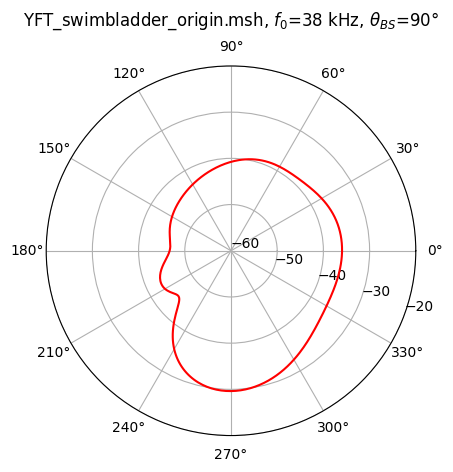

# YFT_swimbladder_origin.msh
# th0=270 ph0=0 f0=38000 c0=1480
0	0.0159184
1	0.0159246
2	0.015926
3	0.0159223
4	0.0159132
5	0.0158984
6	0.0158777
7	0.0158508
8	0.0158175
9	0.0157778
10	0.0157314
11	0.0156783
12	0.0156185
13	0.0155518
14	0.0154784
15	0.0153984
16	0.0153117
17	0.0152187
18	0.0151194
19	0.0150143
20	0.0149034
21	0.0147873
22	0.0146663
23	0.0145408
24	0.0144113
25	0.0142783
26	0.0141424
27	0.0140043
28	0.0138644
29	0.0137235
30	0.0135823
31	0.0134414
32	0.0133014
33	0.0131632
34	0.0130274
35	0.0128945
36	0.0127654
37	0.0126404
38	0.0125203
39	0.0124053
40	0.0122961
41	0.0121929
42	0.0120959
43	0.0120054
44	0.0119215
45	0.0118441
46	0.0117731
47	0.0117084
48	0.0116497
49	0.0115967
50	0.011549
51	0.011506
52	0.0114674
53	0.0114324
54	0.0114006
55	0.0113712
56	0.0113437
57	0.0113175
58	0.0112918
59	0.0112663
60	0.0112401
61	0.0112129
62	0.0111841
63	0.0111533
64	0.01112
65	0.011084
66	0.0110449
67	0.0110024
68	0.0109564
69	0.0109067
70	0.0108533
71	0.010796
72	0.0107349
73	0.0

In [19]:
# MM 19.5.2025: scattering from soft body
# !pip install --force-reinstall "numpy<=2.2" scipy bempp-cl matplotlib

datapath="../msh/"

import bempp_cl as bempp
from bempp_cl.api.operators.boundary import helmholtz as boundary
from bempp_cl.api.operators.potential import helmholtz as potential
from bempp_cl.api.linalg import gmres
#from scipy.linalg import gmres
from numpy import pi, sin, cos, exp, log10, abs, array, linspace

# input parameters
fname = 'sphere-1.905-600.msh'
fname = 'simplify10_YFT_swimbladder_origin.msh'
fname = 'YFT_swimbladder_origin.msh'
th = 270
f0 = 38e3 
c0 = 1480

k0 = 2*pi * f0 / c0                          # wave number
d = array([cos(th*pi/180+pi),sin(th*pi/180+pi),0]) # plane wave direction
#d = array([0, -1.0, 0])                     # plane wave direction

# target mesh and its space
#grid = bempp.api.shapes.sphere(r=0.01905, h=c0/f0/5) # generated mesh
grid = bempp.api.import_grid(datapath + fname)
Sp = bempp.api.function_space(grid, "P", 1)   #, "DP", 0) 

# incident pressure 
@bempp.api.complex_callable
def pinc(x, n, idx, res): res[0] = exp(1j*k0*d.dot(x))
f = bempp.api.GridFunction(Sp, fun=pinc)

# surface solution
S = boundary.single_layer(Sp, Sp, Sp, k0)
u,_ = gmres(S, -f)

# far field solution
#r1 = array([[sin(2*pi*i/360+pi),-cos(2*pi*i/360+pi),0] for i in range(360)]).T
r1 = array([[cos(i*pi/180+pi),sin(i*pi/180+pi),0] for i in range(360)]).T
SL = potential.single_layer(Sp, r1, k0)
psc = - SL.evaluate(u)

# plot mesh
v = grid.vertices.T
e = grid.elements.T
n, m = len(v), len(e)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
tri = [[array(v[i]) for i in t] for t in e]
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
mesh_collection = Poly3DCollection(tri, alpha=0.6)
mesh_collection.set_facecolor('white')
mesh_collection.set_edgecolor('darkblue')
mesh_collection.set_linewidth(0.2)
ax.add_collection3d(mesh_collection)
v_arr = array(v)
x_min, x_max = v_arr[:, 0].min(), v_arr[:, 0].max()
y_min, y_max = v_arr[:, 1].min(), v_arr[:, 1].max()
z_min, z_max = v_arr[:, 2].min(), v_arr[:, 2].max()
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_zlim(z_min, z_max)
x_range = x_max - x_min
y_range = y_max - y_min
z_range = z_max - z_min
ax.set_box_aspect((x_range, y_range, z_range))
ax.view_init(elev=10, azim=20, vertical_axis='y')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.zaxis.set_major_locator(MaxNLocator(nbins=4))
ax.set_title(r"%s, %dx%d"%(fname,n,m))
plt.savefig("yft_bempp_1.svg", format="svg", bbox_inches="tight")
plt.show()

# plot solution
import matplotlib.pyplot as plt
angles = linspace(0, 2*pi, 360, endpoint=False)
values_db = 20 * log10([abs(p) for p in psc[0]])
vmin, vmax = -60, -20
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(angles, values_db, color='red')
ax.set_ylim(vmin, vmax)
ax.set_rticks(linspace(vmin, vmax, 5))
ax.set_xticks(linspace(0, 2*pi - pi/6, 12))  # 30deg
ax.set_rlabel_position(-20)
ax.grid(True)
ax.set_title(r"%s, $f_0$=%g kHz, $\theta_{BS}$=%g$\degree$"%(fname,f0/1e3,(th+180)%360), va='bottom')
plt.savefig("yft_bempp_2.svg", format="svg", bbox_inches="tight")
plt.show()

# print
s = "# %s\n# th0=%g ph0=0 f0=%g c0=%g\n"%(fname,th,f0,c0)
s += "\n".join(["%d\t%g"%(i,abs(psc[0][i])) for i in range(len(psc[0]))])
print(s)
with open("yft_bempp_3.txt", "w") as f: print(s,file=f)
